In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Data/customer_data_dirty.csv")
df.head(5)

,CustomerID,Age,Annual_Income,Spending_Score,Gender,City,Education
0,82,48,NaN,52,Female,New York,Bachelor
1,143,31,34543.5,24,Male,Los Angeles,High School
2,32,44,58081.02,55,Male,Los Angeles,Master
3,30,42,33954.45,92,Male,Houston,High School
4,119,59,54281.87,95,Female,Phoenix,Master


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      155 non-null    int64
 1   Age             150 non-null    str  
 2   Annual_Income   149 non-null    str  
 3   Spending_Score  150 non-null    str  
 4   Gender          155 non-null    str  
 5   City            155 non-null    str  
 6   Education       155 non-null    str  
dtypes: int64(1), str(6)
memory usage: 8.6 KB


In [2]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [3]:
columns = ['Age', 'Spending_Score', 'Annual_Income']

df[columns] = (
    df[columns]
    .replace(r'[$,]', '', regex=True)
    .apply(pd.to_numeric, errors='coerce')
)

df.info()

<class 'pandas.DataFrame'>
Index: 150 entries, 0 to 154
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      150 non-null    int64  
 1   Age             143 non-null    float64
 2   Annual_Income   144 non-null    float64
 3   Spending_Score  143 non-null    float64
 4   Gender          150 non-null    str    
 5   City            150 non-null    str    
 6   Education       150 non-null    str    
dtypes: float64(3), int64(1), str(3)
memory usage: 9.4 KB


In [15]:
df.isnull().sum()

CustomerID        0
Age               7
Annual_Income     6
Spending_Score    7
Gender            0
City              0
Education         0
dtype: int64

In [8]:
df.fillna(df[columns].mean(), inplace=True)
df.isnull().sum()

CustomerID        0
Age               0
Annual_Income     0
Spending_Score    0
Gender            0
City              0
Education         0
dtype: int64

In [5]:
clean_data = pd.get_dummies(df[['City', 'Gender', 'Education']])
clean_data.head(5)

,City_Chicago,City_Chicago,City_Houston,City_Houston,City_LA,City_Los Angeles,City_Los Angeles,City_LosAngles,City_NEW YORK,City_New York,...,Education_High School,Education_High school,Education_Master,Education_Masters,Education_Ph.D,Education_PhD,Education_bachelor,Education_high school,Education_master,Education_phd
0,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,True,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,True,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df[columns]
x_train, x_test = train_test_split(X, test_size=0.2, random_state=42)

scaler = StandardScaler()
x_train_scal = scaler.fit_transform(x_train)
x_test_scal = scaler.transform(x_test)

In [13]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
train_cluster = kmeans.fit_predict(x_train_scal)

In [16]:
from sklearn.metrics import silhouette_score

test_cluster = kmeans.predict(x_test_scal)
test_inertia = -kmeans.score(x_test_scal)
print(f"Test inertia (lower is better): {test_inertia:.3f}")

if len(set(test_cluster)) > 1:
    score = silhouette_score(x_test_scal, test_cluster)
    print(f"Test silhouette score: {score:.3f}")
else:
    print("Test silhouette score is undefined because the test set has only one cluster.")

Test inertia (lower is better): 25.620
Test silhouette score is undefined because the test set has only one cluster.


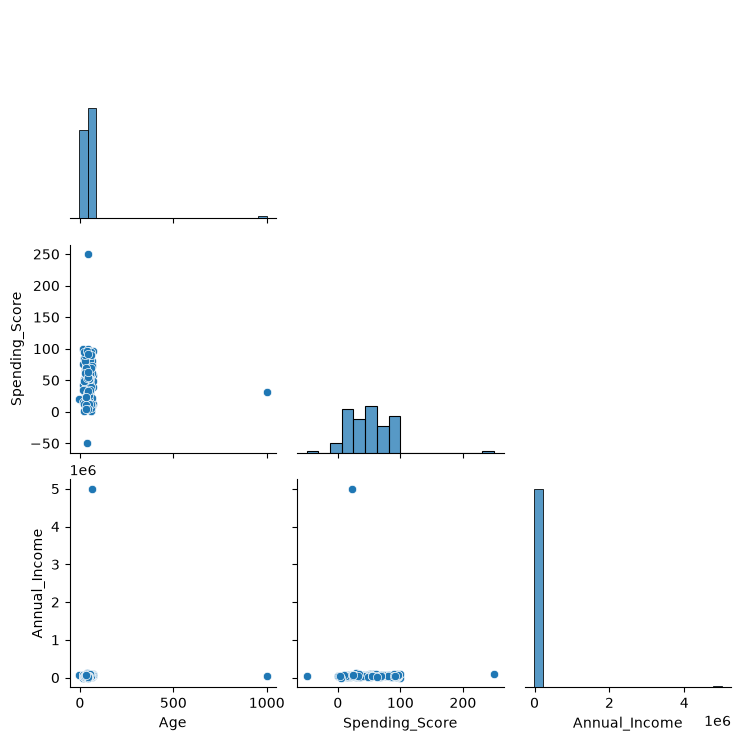

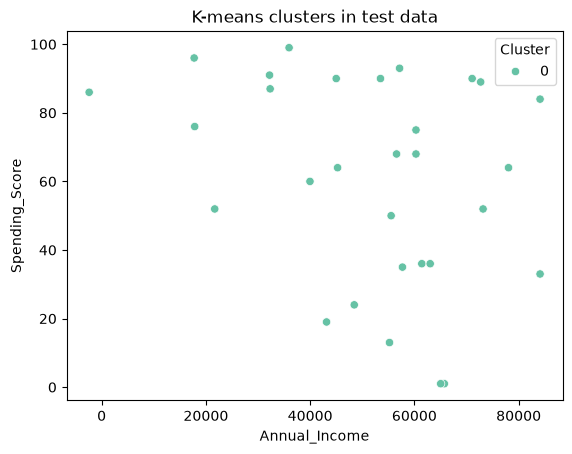

In [17]:
sns.pairplot(x_train, corner=True)
plt.show()

test_plot = x_test.copy()
test_plot["Cluster"] = test_cluster
sns.scatterplot(
    data=test_plot,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="Set2",
)
plt.title("K-means clusters in test data")
plt.show()